# Creating an Reservoir Artificial Metabolic (AMN) Reservoir with **Aida & Ying (2025)** experimental medium


This notebook demonstrates the pipeline for using AMNs with a large-scale dataset of *Escherichia coli* growth under well-defined laboratory conditions (Aida & Ying, 2025). The purpose if to use this dataset for training Artificial Metabolic Networks (Faure et al., 2023) that can learn to map `media concentration` $\rightarrow$ `uptake flux`

---

Aida, H., & Ying, B. (2025). Population Dynamics of Escherichia coli Growing under Chemically Defined Media. Scientific Data, 12(1), 984. https://doi.org/10.1038/s41597-025-05356-3

## Set up environment

In [1]:
# Automatic module reloading
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import r2_score

# Set up paths
from pathlib import Path

current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent

# Add root to sys.path so 'src' imports work
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
DATA_INTERIM_DIR = PROJECT_ROOT / 'data' / 'interim'
DATA_EXTERNAL_DIR = PROJECT_ROOT / 'data' / 'external'
MODEL_DIR = PROJECT_ROOT / 'models'


In [2]:
# filter out INFO, WARNING, and ERROR logs
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 

import tensorflow as tf
tf.get_logger().setLevel('ERROR')  # suppress Python-level TF warnings

# Check GPU availability
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPUs: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow Version: 2.15.1
GPUs: 0


## Step 1: Prepare Genome-Scale Model

A requirement for neural computations with metabolic networks using AMNs is the positivity of all fluxes. This means duplicating the reversible reactions in the Genome-Scale Model (GEM) used, making it irreversible.

The following steps transform an SBML model into an *AMN-compatible*  model where: **all exchange reactions are possible in both ways, and reversible internal reactions are duplicated for each way**.

In [3]:
# Import the module
from src.Duplicate_Model import *

In [4]:
# iML1515 model
model_path = DATA_RAW_DIR / "iML1515.xml"
model = cobra.io.read_sbml_model(model_path)

In [5]:
# Boundary reactions
# reactions that introduce or remove matter in the system (inflows, outflows)
boundary_rxns = model.boundary
print(f"Total number of boundary reactions: {len(boundary_rxns)}")
    
# Medium reactions
# reactions in .boundary that are reversible
medium_rxns = model.medium
print(f"\nTotal number of medium reactions: {len(medium_rxns)}")
print(f"All medium reactions: {medium_rxns}")


Total number of boundary reactions: 337

Total number of medium reactions: 24
All medium reactions: {'EX_pi_e': 1000.0, 'EX_co2_e': 1000.0, 'EX_fe3_e': 1000.0, 'EX_h_e': 1000.0, 'EX_mn2_e': 1000.0, 'EX_fe2_e': 1000.0, 'EX_glc__D_e': 10.0, 'EX_zn2_e': 1000.0, 'EX_mg2_e': 1000.0, 'EX_ca2_e': 1000.0, 'EX_ni2_e': 1000.0, 'EX_cu2_e': 1000.0, 'EX_sel_e': 1000.0, 'EX_cobalt2_e': 1000.0, 'EX_h2o_e': 1000.0, 'EX_mobd_e': 1000.0, 'EX_so4_e': 1000.0, 'EX_nh4_e': 1000.0, 'EX_k_e': 1000.0, 'EX_na1_e': 1000.0, 'EX_cl_e': 1000.0, 'EX_o2_e': 1000.0, 'EX_tungs_e': 1000.0, 'EX_slnt_e': 1000.0}


In [6]:
io_dict = {"_i": [(None, "e"), (None, "c"), ("e","p"), ("p", "c"), ("e", "c"), ("c", "m"), ("p", "m")],
           "_o": [("c", None), ("e", None), ("p", "e"), ("c", "p"), ("c", "e"), ("m", "c"), ("m", "p")]}

unsignificant_mols = ["h_p", "h_c", "pi_c", "pi_p", "adp_c", "h2o_c", "atp_c"]

# Dictionary counting the reactions in reversible, forward, backward, open 
reac_id_to_io_count_and_way = screen_out_in(model, io_dict, unsignificant_mols)

# Structure of the screening dictionary
print()
print(reac_id_to_io_count_and_way)

{'r': 663, 'f': 2047, 'b': 0, 'o': 2}

{'NDPK5': [{'_i': 0, '_o': 0}, 'r'], 'SHK3Dr': [{'_i': 0, '_o': 0}, 'r'], 'NDPK6': [{'_i': 0, '_o': 0}, 'r'], 'NDPK8': [{'_i': 0, '_o': 0}, 'r'], 'DHORTS': [{'_i': 0, '_o': 0}, 'r'], 'PYNP2r': [{'_i': 0, '_o': 0}, 'r'], 'ICDHyr': [{'_i': 0, '_o': 0}, 'r'], 'DURIPP': [{'_i': 0, '_o': 0}, 'r'], 'ACALD': [{'_i': 0, '_o': 0}, 'r'], 'MAN6PI': [{'_i': 0, '_o': 0}, 'r'], 'TRPAS2': [{'_i': 0, '_o': 0}, 'r'], 'ALAR': [{'_i': 0, '_o': 0}, 'r'], 'ALATA_L': [{'_i': 0, '_o': 0}, 'r'], 'PPM': [{'_i': 0, '_o': 0}, 'r'], 'ASPTA': [{'_i': 0, '_o': 0}, 'r'], 'EX_pi_e': [{'_i': 0, '_o': 1}, 'r'], 'EX_co2_e': [{'_i': 0, '_o': 1}, 'r'], 'A5PISO': [{'_i': 0, '_o': 0}, 'r'], 'EX_met__L_e': [{'_i': 0, '_o': 1}, 'f'], 'GTHOr': [{'_i': 0, '_o': 0}, 'r'], 'ILETA': [{'_i': 0, '_o': 0}, 'r'], 'EX_metsox_S__L_e': [{'_i': 0, '_o': 1}, 'f'], 'VALTA': [{'_i': 0, '_o': 0}, 'r'], 'IPPMIb': [{'_i': 0, '_o': 0}, 'r'], 'ORPT': [{'_i': 0, '_o': 0}, 'r'], 'PSCVT': [{'_i': 0, '_o': 0}, '

In [7]:
# Use the dictionary to generate the AMN-compatible model
new_model = duplicate_model(model, reac_id_to_io_count_and_way)

The default model had 2712 reactions and the duplicated-reactions model has 3682 reactions.


In [8]:
# all non-default medium exchange reactions with UB=0 are set to 1e-300
# so they still appear in the medium object.
default_med = model.medium
new_med = new_model.medium
correct_med =  correct_duplicated_med(default_med, new_med)
new_model.medium = correct_med

print(f"Default medium: {len(default_med)} compounds")
print(f"\nCorrected medium: {len(correct_med)} compounds")

Default medium: 24 compounds

Corrected medium: 331 compounds


In [9]:
# Convert corrected medium to a pandas DataFrame
df_med = pd.DataFrame(list(correct_med.items()), columns=['rxn', 'value'])

# Save corrected medium as a csv
df_med.to_csv(DATA_INTERIM_DIR / 'iML1515_medium_corrected.csv', index=False)


In [10]:
# Rebuild indices and pointers in the model if necessary
new_model.repair() 

In [11]:
new_model_path = DATA_INTERIM_DIR / "iML1515_duplicated.xml"
cobra.io.write_sbml_model(new_model, new_model_path)

print("Original model's location: " + str(model_path))
print("Duplicated model's location: " + str(new_model_path))

Original model's location: /scratch/chinasse/BactoCat-AMN/data/raw/iML1515.xml
Duplicated model's location: /scratch/chinasse/BactoCat-AMN/data/interim/iML1515_duplicated.xml


## Step 2. Aida & Ying Dataset Pre-processing
#### 2.1. Match the Aida & Ying Compounds to iML1515 reactions

In [12]:
from src.data_preprocess import *

In [13]:
# Map Aida & Ying compounds to iML1515 reactions
model_path = DATA_RAW_DIR / "iML1515.xml"
mapping_csv = create_supplementary_csv(model, DATA_INTERIM_DIR)

Total AIDA compounds in mapping: 40


In [14]:
# Create media dataframe
mapping_csv = DATA_INTERIM_DIR / "aidaying_compound_mapping.csv"
final_df = create_media_growth_csv(DATA_EXTERNAL_DIR, mapping_csv, DATA_INTERIM_DIR)

Mapped 40 AIDA columns into 37 GEM reactions.
6 media columns were not mapped.
Columns not renamed: ['Label', 'Assay ID', 'FolicAcid (mM)', 'Riboflavin (mM)', 'H3BO3 (mM)', 'AminobenzoicAcid (mM)']
Media compositions before dropping duplicates → 13608
Unique media compositions after dropping duplicates → 941
Total growth entries in CSV: 13608
Entries with r_info = 1: 262
Entries with r_info = 2: 475
Growth entries remaining (r_info = 0): 12871
Final unique conditions → 924
Final media data saved to /scratch/chinasse/BactoCat-AMN/data/interim/aidaying_media_growth_amns.csv


In [15]:
# Correct the csv to keep only the duplicated model media reactions
corrected_df = match_amns_media(DATA_INTERIM_DIR, DATA_INTERIM_DIR, final_df)

Columns matched and renamed with AMNS reference: 37/37
Final media data saved to /scratch/chinasse/BactoCat-AMN/data/interim/aidaying_media_growth_amns.csv


#### 2.2. Generate parameter file for `FBA-simulated` training set

An `FBA-simulated` dataset will be generated for training the AMN Reservoir. The reservoir learns the stoichiometric and bound constraints of the GEM from diverse FBA solutions. Thus, the training dataset should:

1. Cover diverse flux patterns
2. All produce growth > 0 - no infeasible conditions

#### Parameters for random generation

A file with parameters for random generation for the `FBA-simulated` dataset is needed. It's a csv specifying:

- `level`: Number of discrete levels each medium flux can take.
    - `level` <= 1: Minimum medium (always on at a fixed value).
    - `level` > 1: Variable medium (can be turned on/off with multiple levels).

- `max_level`: Maximum value each medium flux can take. Used to compute the actual flux value when a variable medium is turned on.

- `ratio_drawing`: Ratio/probability of variable medium fluxes being turned on during random generation. Not used when `max_level` is provided

We will be using the parameter file from Faure et. al (2023). 

In [16]:
# Load Aida & Yin dataset (already processed to match model's reactions)
aida_path = DATA_INTERIM_DIR / "aidaying_media_growth_amns.csv"
aida_df = pd.read_csv(aida_path)

# Compounds in the Aida & Ying dataset
print(f"Aida & Ying DataFrame shape: {aida_df.shape}")
print(f"Columns: {aida_df.columns.tolist()}")

Aida & Ying DataFrame shape: (924, 38)
Columns: ['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_nh4_e_i', 'EX_so4_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_mg2_e_i', 'EX_ca2_e_i', 'EX_fe2_e_i', 'EX_zn2_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i', 'GR_AVG']


In [17]:
# EDA on aida_df
global_min = aida_df.min().min()
global_max = aida_df.max().max()
print(f"Minimum across all columns: {global_min}")
print(f"Maximum across all columns: {global_max}")


Minimum across all columns: 0.0
Maximum across all columns: 343.0


In [18]:
# Load parameter file from Faure et. al 
faure_path = DATA_EXTERNAL_DIR / "faure_parameters.csv"
faure_params_df = pd.read_csv(faure_path)

# Compounds in the Faure et. al parameter file
print(f"Faure DataFrame shape: {faure_params_df.shape}")
print(f"Columns: {faure_params_df.columns.tolist()}")
faure_params_df.head(3)

Faure DataFrame shape: (4, 39)
Columns: ['name', 'EX_pi_e_i', 'EX_co2_e_i', 'EX_fe3_e_i', 'EX_h_e_i', 'EX_mn2_e_i', 'EX_fe2_e_i', 'EX_zn2_e_i', 'EX_mg2_e_i', 'EX_ca2_e_i', 'EX_ni2_e_i', 'EX_cu2_e_i', 'EX_sel_e_i', 'EX_cobalt2_e_i', 'EX_h2o_e_i', 'EX_mobd_e_i', 'EX_so4_e_i', 'EX_nh4_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_cl_e_i', 'EX_o2_e_i', 'EX_tungs_e_i', 'EX_slnt_e_i', 'EX_glyc_e_i', 'EX_ala__L_e_i', 'EX_pro__L_e_i', 'EX_thr__L_e_i', 'EX_gly_e_i', 'EX_rib__D_e_i', 'EX_malt_e_i', 'EX_melib_e_i', 'EX_tre_e_i', 'EX_fru_e_i', 'EX_gal_e_i', 'EX_ac_e_i', 'EX_lac__D_e_i', 'EX_succ_e_i', 'EX_pyr_e_i']


,name,EX_pi_e_i,EX_co2_e_i,EX_fe3_e_i,EX_h_e_i,EX_mn2_e_i,EX_fe2_e_i,EX_zn2_e_i,EX_mg2_e_i,EX_ca2_e_i,...,EX_rib__D_e_i,EX_malt_e_i,EX_melib_e_i,EX_tre_e_i,EX_fru_e_i,EX_gal_e_i,EX_ac_e_i,EX_lac__D_e_i,EX_succ_e_i,EX_pyr_e_i
0,level,1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1,max_value,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,...,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2
2,ratio_drawing,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# Store column names (excluding non-compounds)
faure_cols = faure_params_df.columns.drop('name')
aida_cols = aida_df.columns.drop('GR_AVG')

print(f"Faure compounds: {len(faure_cols)}")
print(f"Aida & Ying compounds: {len(aida_cols)}")

Faure compounds: 38
Aida & Ying compounds: 37


In [20]:
# Check common compounds
common_compounds = set(faure_cols) & set(aida_cols)
print(f"Common compounds: {len(common_compounds)}")
print(f"Common compounds: {common_compounds}")

# Check Aida only
aida_only = set(aida_cols) - set(faure_cols)
print(f"\nAida & Ying only compounds: {len(aida_only)}")
print(f"Aida & Ying only compounds: {aida_only}")

# Check Faure only
faure_only = set(faure_cols) - set(aida_cols)
print(f"\nFaure only compounds: {len(faure_only)}")
print(f"Faure only compounds: {faure_only}")

Common compounds: 16
Common compounds: {'EX_k_e_i', 'EX_pi_e_i', 'EX_thr__L_e_i', 'EX_mg2_e_i', 'EX_nh4_e_i', 'EX_pro__L_e_i', 'EX_so4_e_i', 'EX_cl_e_i', 'EX_cu2_e_i', 'EX_fe2_e_i', 'EX_mobd_e_i', 'EX_ala__L_e_i', 'EX_na1_e_i', 'EX_ca2_e_i', 'EX_gly_e_i', 'EX_zn2_e_i'}

Aida & Ying only compounds: 21
Aida & Ying only compounds: {'EX_arg__L_e_i', 'EX_his__L_e_i', 'EX_asp__L_e_i', 'EX_cit_e_i', 'EX_cys__L_e_i', 'EX_tyr__L_e_i', 'EX_met__L_e_i', 'EX_ser__L_e_i', 'EX_pydxn_e_i', 'EX_val__L_e_i', 'EX_gln__L_e_i', 'EX_tsul_e_i', 'EX_asn__L_e_i', 'EX_glu__L_e_i', 'EX_glc__D_e_i', 'EX_leu__L_e_i', 'EX_trp__L_e_i', 'EX_phe__L_e_i', 'EX_ile__L_e_i', 'EX_thm_e_i', 'EX_lys__L_e_i'}

Faure only compounds: 22
Faure only compounds: {'EX_h_e_i', 'EX_mn2_e_i', 'EX_h2o_e_i', 'EX_pyr_e_i', 'EX_cobalt2_e_i', 'EX_sel_e_i', 'EX_malt_e_i', 'EX_ac_e_i', 'EX_melib_e_i', 'EX_ni2_e_i', 'EX_glyc_e_i', 'EX_tungs_e_i', 'EX_gal_e_i', 'EX_co2_e_i', 'EX_fe3_e_i', 'EX_lac__D_e_i', 'EX_o2_e_i', 'EX_rib__D_e_i', 'EX_tre_

We need to create a parameter file with the compounds from the Aida & Ying dataset. This way, the reservoir will have seen flux patterns involving the experimental compounds.

We can classify the Aida & Ying only compounds in 5 categories:
- 2 carbon sources
- 3 vitamins
- 4 major salts
- 2 minor ions
- 4 aminoacids
- 6 essential compounds*

These can be can be ON/OFF, meaning they can vary (`level`: 100) at different max values. `max_value` is in units of upper bounds (mmol/gDW/h).

The essential compounds* are needed for growth, meaning they cannot vary (`level`: 1) and we set them to a flat value of 2.2 (following Faure's method) to allow unlimited supply.

In [21]:
# Classify Aida & Ying compounds

carbon_sources = ['EX_glc__D_e_i', 'EX_cit_e_i']
vitamins = ['EX_thm_e_i', 'EX_pydxn_e_i', 'EX_tsul_e_i']
major_salts = ['EX_na1_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_cl_e_i']
minor_ions = ['EX_mobd_e_i', 'EX_cu2_e_i']
essential = ['EX_mg2_e_i', 'EX_nh4_e_i', 'EX_so4_e_i', 'EX_zn2_e_i', 'EX_ca2_e_i', 'EX_fe2_e_i']


aida_compounds = carbon_sources + vitamins + major_salts + minor_ions
new_data = {}

for compound in aida_cols:
    if compound in carbon_sources:
        level_val = 100
        max_val = 10
    elif compound in vitamins:
        level_val = 100
        max_val = 0.0001
    elif compound in major_salts:
        level_val = 100
        max_val = 5.0
    elif compound in minor_ions:
        level_val = 100
        max_val = 0.0001
    elif compound in essential:
        level_val = 1
        max_val = 2.2
    else: # aminoacids
        level_val = 100
        max_val = 0.1
    # Assign the classification
    new_data[compound] = [level_val, max_val, np.nan, np.nan]

new_cols_df = pd.DataFrame(new_data)
print(f"New columns dataframe: {new_cols_df.shape}")

New columns dataframe: (4, 37)


In [22]:
print(f"Original Faure parameter file shape: {faure_params_df.shape}")

faure_carbon = ['EX_glyc_e_i', 'EX_rib__D_e_i', 'EX_malt_e_i', 'EX_melib_e_i', 'EX_tre_e_i', 'EX_fru_e_i', 
                'EX_gal_e_i', 'EX_ac_e_i', 'EX_lac__D_e_i', 'EX_succ_e_i', 'EX_pyr_e_i']

# Remove Faure-only carbon sources
faure_params_df = faure_params_df.drop(columns=faure_carbon)

# Removing the common compounds (will used the assigned values above)
faure_params_df = faure_params_df.drop(columns=common_compounds)

print(f"Clean Faure parameter file shape (only with environmental compounds): {faure_params_df.shape}")

Original Faure parameter file shape: (4, 39)
Clean Faure parameter file shape (only with environmental compounds): (4, 12)


In [23]:
new_cols_df = pd.DataFrame(new_data)
new_params_df = pd.concat([faure_params_df, new_cols_df], axis=1)

print(f"Parameter file with environmental compounds and Aida & Ying compounds: {new_params_df.shape}")

new_params_df.head(3)

Parameter file with environmental compounds and Aida & Ying compounds: (4, 49)


,name,EX_co2_e_i,EX_fe3_e_i,EX_h_e_i,EX_mn2_e_i,EX_ni2_e_i,EX_sel_e_i,EX_cobalt2_e_i,EX_h2o_e_i,EX_o2_e_i,...,EX_k_e_i,EX_na1_e_i,EX_mg2_e_i,EX_ca2_e_i,EX_fe2_e_i,EX_zn2_e_i,EX_cu2_e_i,EX_mobd_e_i,EX_cit_e_i,EX_tsul_e_i
0,level,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,100.0,100.0,1.0,1.0,1.0,1.0,100.0000,100.0000,100.0,100.0000
1,max_value,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,...,5.0,5.0,2.2,2.2,2.2,2.2,0.0001,0.0001,10.0,0.0001
2,ratio_drawing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
new_params_df.to_csv(DATA_PROCESSED_DIR / 'aidaying_parameters.csv', index=False)

#### 2.3. Padding the Aida & Ying dataset

Because the AMN reservoir training data must match the experimental data (have the same type and number of `compounds`), the Aida & Ying dataset must be padded with the compounds in the Faure dataset. 

- **Compounds present but not measured**
   - Correspond to environmental conditions (`EX_o2_e_i`, `EX_co2_e_i`, ...)
   - These will be constant across all rows
   - **WIP:** There's 2 routes to assign values
      - Values (in mM) were selected from standard *E. coli* defined media concentrations
      - Values to match parameter file (the flat 2.2). This is *unrealistic* for media conc. But it's like assuming *unlimited* supply of these nutrients.
 - **Compounds genuinely absent**     
   - Other carbon sources (`EX_glyc_e_i`, `EX_malt_e_i`, ...)
   - These will be discarded

*Note on H₂O:*
- A common value for water concentration in media is 55,000 mM, but this will be is an outlier that could dominate the feature space
- To prevent distorting the input distribution, we assign 2.2 (same value as cofactors)

In [25]:
# Compounds present (environmental/essential) 
# but not measured in Aida & Ying

# Values (in mM) selected from standard E. coli defined media concentrations
unmeasured_compounds = {
    'EX_o2_e_i': 0.21,
    'EX_co2_e_i': 0.013,
    'EX_h_e_i': 0.0001,
    'EX_h2o_e_i': 2.2,
    'EX_fe3_e_i': 0.0005,
    'EX_mn2_e_i': 0.0001,
    'EX_ni2_e_i': 0.0001,
    'EX_sel_e_i': 0.0001,
    'EX_cobalt2_e_i': 0.0001,
    'EX_tungs_e_i': 0.0001,
    'EX_slnt_e_i': 0.0001
}

# Values to match parameter file (the flat 2.2)
# unmeasured_compounds = {
#     'EX_o2_e_i': 2.2,
#     'EX_co2_e_i': 2.2,
#     'EX_h_e_i': 2.2,
#     'EX_h2o_e_i': 2.2,
#     'EX_fe3_e_i': 2.2,
#     'EX_mn2_e_i': 2.2,
#     'EX_ni2_e_i': 2.2,
#     'EX_sel_e_i': 2.2,
#     'EX_cobalt2_e_i': 2.2,
#     'EX_tungs_e_i': 2.2,
#     'EX_slnt_e_i': 2.2
# }

compounds_to_add = {**unmeasured_compounds}

In [26]:
# Pad the Aida & Ying dataset with the missing compounds from the Faure dataset

print(f"Original Aida shape: {aida_df.shape}")

# Temporarily remove GR_AVG to preserve order
gr_avg_col = aida_df.pop('GR_AVG')

# Create a DataFrame with the new columns
new_data = {
    col: val 
    for col, val in compounds_to_add.items()
}
new_cols_df = pd.DataFrame(new_data, index=aida_df.index)

# Concatenate
aida_df = pd.concat([aida_df, new_cols_df], axis=1)

# Add GR_AVG back as last column
aida_df['GR_AVG'] = gr_avg_col

# Remove first row (zero growth, might bias the model)
aida_df = aida_df.iloc[1:]

print(f"New Aida shape: {aida_df.shape}")

Original Aida shape: (924, 38)
New Aida shape: (923, 49)


In [27]:
# Export
aida_df.to_csv(DATA_INTERIM_DIR / 'aidaying_media_growth_amns_padded.csv', index=False)

## Step 3. Generate `FBA-simulated` training set for Reservoir AMN

An `FBA-simulated` dataset will be generated for the AMN Reservoir with experimental data.
This generation relies on using the Aida & Ying Dataset, a csv where `rows = conditions` and `cols = exchanges`+`growth_value`.

We use the padded version from the previous step.

### 3.1 Retrieve compounds in Aida & Ying padded

In [28]:
from src.Build_Dataset import *

# Set parameters
seed = 10
np.random.seed(seed=seed)  # seed for random number generator
cobraname =  'iML1515_duplicated' # name of the model 
mediumbound = 'UB' # Exact bound (EB) or upper bound (UB)
expname = 'aidaying_media_growth_amns_padded' # name of the experimental dataset for constraints
size, size_i  = 924, 50 # (# of exp conditions, training set size per condition)
reduce = False # Set at True if you want to reduce the model
mediumsize = 48 # number of medium compounds
verbose = True # prints

# Get X from experimental dataset
cobrafile = DATA_INTERIM_DIR / cobraname # .xml
expfile  = DATA_INTERIM_DIR / expname # .csv

# Generate a parameter object with the experimental data
parameter = TrainingSet(cobraname=str(cobrafile), 
                        mediumname=str(expfile), 
                        mediumbound=mediumbound, 
                        mediumsize=mediumsize, 
                        method='EXP',
                        verbose=verbose)


medium: ['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_nh4_e_i', 'EX_so4_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_mg2_e_i', 'EX_ca2_e_i', 'EX_fe2_e_i', 'EX_zn2_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i', 'EX_o2_e_i', 'EX_co2_e_i', 'EX_h_e_i', 'EX_h2o_e_i', 'EX_fe3_e_i', 'EX_mn2_e_i', 'EX_ni2_e_i', 'EX_sel_e_i', 'EX_cobalt2_e_i', 'EX_tungs_e_i', 'EX_slnt_e_i']
levmed: []
valmed: []
ratmed: 0
objective:  ['BIOMASS_Ec_iML1515_core_75p37M']
measurements size:  3682


In [29]:
# Store the medium data 
# (X matrix, where rows are conditions and columns are compounds)
X = parameter.X.copy()
print("X shape:")
print(X.shape)
print("X:")
print(f"{X}\n")

# Store the growth data 
# (Y vector, where each element is the growth rate of the condition)
Y = parameter.Y.copy()
print("Y shape:")
print(Y.shape)
print("Y:")
print(f"{Y}")

X shape:
(924, 48)
X:
[[2.000e+00 2.000e-02 2.000e-02 ... 2.200e+00 2.200e+00 2.200e+00]
 [2.000e+00 2.000e-02 2.000e-02 ... 2.200e+00 2.200e+00 2.200e+00]
 [2.000e+00 2.000e-02 2.000e-02 ... 2.200e+00 2.200e+00 2.200e+00]
 ...
 [4.342e+01 4.800e-01 4.600e-01 ... 2.200e+00 2.200e+00 2.200e+00]
 [4.342e+01 4.800e-01 4.600e-01 ... 2.200e+00 2.200e+00 2.200e+00]
 [4.342e+01 4.800e-01 4.600e-01 ... 2.200e+00 2.200e+00 2.200e+00]]

Y shape:
(924, 1)
Y:
[[0.        ]
 [1.35195701]
 [1.21247769]
 [1.31664145]
 [1.20613912]
 [1.2096604 ]
 [1.18665536]
 [1.2630026 ]
 [1.30251915]
 [1.16141401]
 [1.29121789]
 [1.19038438]
 [1.13983402]
 [0.93687068]
 [1.26857109]
 [1.05723604]
 [0.94498256]
 [1.1675341 ]
 [1.21453758]
 [1.15494106]
 [1.04952889]
 [1.22009679]
 [1.24604945]
 [1.16347754]
 [1.19674906]
 [1.23475186]
 [1.28648177]
 [1.22757426]
 [1.20015331]
 [1.15708897]
 [1.13678278]
 [1.15224194]
 [1.1473662 ]
 [1.07225977]
 [1.20539115]
 [1.12868891]
 [1.11913337]
 [1.06169291]
 [1.0134549 ]
 [

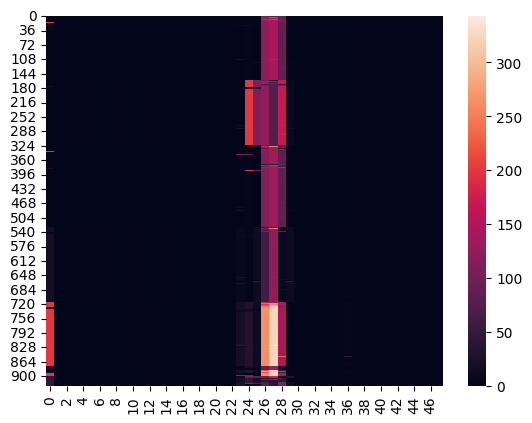

In [30]:
# Heatmap of the medium (conditions, compounds)
sns.heatmap(pd.DataFrame(X))
plt.show()

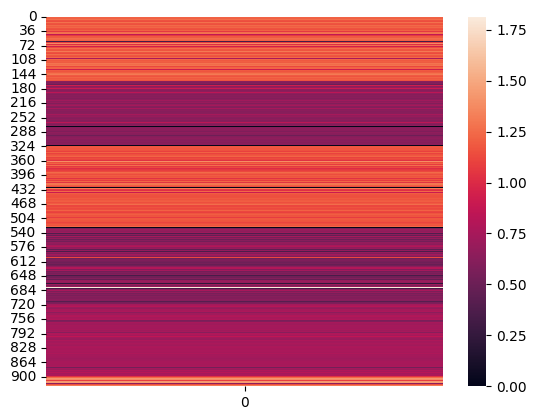

In [31]:
# Heatmap of the growth (conditions)
sns.heatmap(pd.DataFrame(Y))
plt.show()

In [32]:
# Get parameter object for reservoir training set from a medium file
# 'method' is pFBA because this file contains parameters for random generation
mediumfile = DATA_PROCESSED_DIR / 'aidaying_parameters' #.csv
parameter = TrainingSet(cobraname=str(cobrafile), 
                        mediumname=str(mediumfile), 
                        mediumbound=mediumbound, 
                        method='pFBA',
                        verbose=verbose)

medium: ['EX_co2_e_i', 'EX_fe3_e_i', 'EX_h_e_i', 'EX_mn2_e_i', 'EX_ni2_e_i', 'EX_sel_e_i', 'EX_cobalt2_e_i', 'EX_h2o_e_i', 'EX_o2_e_i', 'EX_tungs_e_i', 'EX_slnt_e_i', 'EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_nh4_e_i', 'EX_so4_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_mg2_e_i', 'EX_ca2_e_i', 'EX_fe2_e_i', 'EX_zn2_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i']
levmed: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 1.0, 1.0, 100.0, 100.0,

In [33]:
# Create varmed: the list of variable compound IDs, based on experimental file (X)
from typing import Any

varmed_dict = {}

for i in range(X.shape[0]):
    varmed_dict[i] = []
    for j in range(X.shape[1]):
        if parameter.levmed[j] > 1 and X[i, j] > 0:
            varmed_dict[i].append(parameter.medium[j])

In [34]:
# Extract the values as lists of lists
varmed_all = list(varmed_dict.values())

# Convert inner lists to tuples and deduplicate while preserving order
unique_tuples = dict.fromkeys(tuple(row) for row in varmed_all)

# Convert the unique keys (tuples) back into lists
varmed = [list(unique_item) for unique_item in unique_tuples]

print(f"Original varmed len: {len(varmed_all)}")
print(f"Unique varmed len: {len(varmed)}")
print(varmed)

Original varmed len: 924
Unique varmed len: 50
[['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i'], ['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit

### 3.2. Creating the `FBA-simulated` dataset

For each condition (`varmed[i]`) generate `size_i` iterations of FBA-simulated data.

e.g. if `varmed[i] = 924` and `size_i = 20`, the `trainingsize = (924*20) = 18,480` 

### Explanation of `varmed`
`varmed` is a list that contains the compound IDs present per condition
- `varmed[0] = ['EX_gal_e_i']`: Condition 0 has only galactose as a variable medium
- `varmed[10] = ['EX_melib_e_i', 'EX_gal_e_i']`: Condition 10 has melibiose and galactose

**This is run separately with the script `scripts/create_reservoir_training_dataset.py` to speed up the process with parallelization**

Run  
```bash
python scripts/create_reservoir_training_dataset.py configs/reservoir_training_dataset.yaml
```

In [35]:
size_i = 3 # samples to generate per condition

#Get a COBRApy-generated training set constrained by varmed
for i in range(X.shape[0]): 
    try:
        print(f"Condition {i}: {varmed[i]}")
        parameter.get(sample_size=size_i, varmed=varmed[i], verbose=True)
    except Exception as e:
        print(f"Skipping condition {i} (varmed={varmed[i]}): {e}")
        continue


Condition 0: ['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i']
sample: 0
pass (varmed, obj): ['EX_thm_e_i', 'EX_gly_e_i', 'EX_glu__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_pydxn_e_i', 'EX_phe__L_e_i', 'EX_cu2_e_i', 'EX_met__L_e_i', 'EX_ala__L_e_i', 'EX_val__L_e_i', 'EX_pro__L_e_i', 'EX_tyr__L_e_i', 'EX_gln__L_e_i', 'EX_lys__L_e_i', 'EX_cl_e_i', 'EX_pi_e_i', 'EX_mobd_e_i', 'EX_cys__L_e_i', 'EX_leu__L_e_i', 'EX_na1_e_i', 'EX_tsul_e_i', 'EX_his__L_e_i', 'EX_k_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_glc__D_e_i', 'EX_ser__L_e_i', 'EX_asp__L_e_i'

: 

: 

In [1]:
# Saving files (npz and xml)
# trainingfile  = DATA_PROCESSED_DIR / 'aidaying_iml1515_'+parameter.mediumbound
# parameter.save(trainingfile, reduce=False)

**Here you place the outputs from `scripts/create_reservoir_training_dataset.py`**

In [3]:
# Verifying
from src.Build_Dataset import *

run_id = 'aidaying_iml1515_UB' 
trainingfile = DATA_PROCESSED_DIR / run_id / 'aidaying_iml1515_UB'
parameter = TrainingSet()
parameter.load(str(trainingfile))
print(str(trainingfile))
parameter.printout()

/scratch/chinasse/BactoCat-AMN/data/processed/aidaying_iml1515_UB/aidaying_iml1515_UB
model file name: /scratch/chinasse/BactoCat-AMN/data/processed/aidaying_iml1515_UB/aidaying_iml1515_UB
reduced model: False
medium file name: /scratch/chinasse/BactoCat-AMN/data/processed/aidaying_parameters
medium bound: UB
list of reactions in objective: ['BIOMASS_Ec_iML1515_core_75p37M']
method: pFBA
trainingsize: 10000
list of medium reactions: 48
list of medium levels: 48
list of medium values: 48
ratio of variable medium turned on: nan
list of measured reactions: 3682
Stoichiometric matrix (1877, 3682)
Boundary matrix from reactions to medium: (48, 3682)
Measurement matrix from reaction to measures: (3682, 3682)
Reaction to metabolite matrix: (1877, 3682)
Metabolite to reaction matrix: (3682, 1877)
Training set X: (10000, 48)
Training set Y: (10000, 3682)
S_int matrix (1845, 3682)
S_ext matrix (3682, 7436)
Q matrix (3682, 1845)
P matrix (3682, 3682)
b_int vector (1845,)
b_ext vector (10000, 7436

In [4]:
# X training matrix (trainingsize, compounds)
X_fba_simulated = parameter.X.copy()
print("X shape (conditions, compounds):")
print(X_fba_simulated.shape)
print("X:")
print(f"{X_fba_simulated}\n")

# Y training matrix (trainingsize, flux values)
Y_fba_simulated = parameter.Y.copy()
print("Y shape (conditions, flux values):")
print(Y_fba_simulated.shape)
print("Y:")
print(f"{Y_fba_simulated}")

X shape (conditions, compounds):
(10000, 48)
X:
[[2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 7.43434343e-04
  2.87676768e+02 9.37373737e-04]
 [2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 5.81818182e-04
  1.32525253e+02 1.87474747e-03]
 [2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 2.97373737e-03
  8.40404040e+01 1.42222222e-03]
 ...
 [2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 1.16868687e-03
  1.02424242e+02 1.96969697e-04]
 [2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 6.30303030e-04
  7.22222222e+01 1.28686869e-03]
 [2.20000000e+00 2.20000000e+00 2.20000000e+00 ... 1.01111111e-03
  8.53535354e+01 3.15151515e-04]]

Y shape (conditions, flux values):
(10000, 3682)
Y:
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


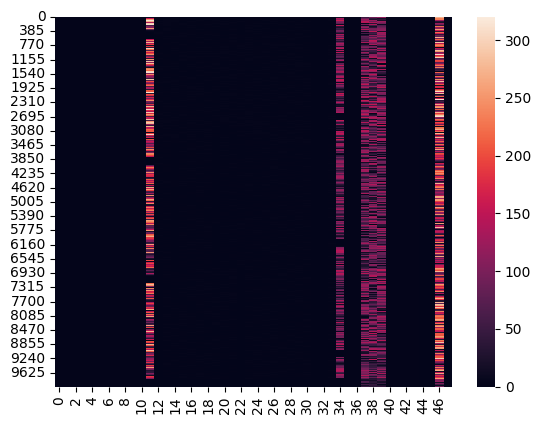

In [5]:
# Heatmap of X (trainingsize, compounds)
sns.heatmap(pd.DataFrame(parameter.X))
plt.show()

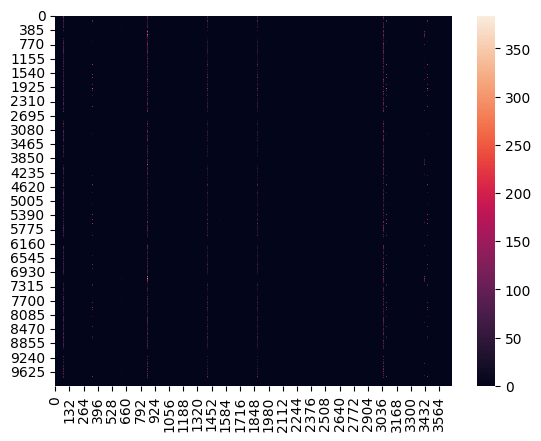

In [6]:
# Heatmap of Y (trainingsize, flux values)
sns.heatmap(pd.DataFrame(parameter.Y))
plt.show()

### Investigating datasets

In [13]:
import numpy as np

# Load npz files
old_data = np.load(PROJECT_ROOT / 'data/processed/iML1515/iML1515_UB.npz')
new_data = np.load(PROJECT_ROOT / 'data/processed/aidaying_iml1515_UB/aidaying_iml1515_UB.npz')

# Compare X distributions
print("Old X stats:", "mean:", old_data['Y'].mean(), "std:", old_data['Y'].std(), "min:", old_data['Y'].min(), "max:", old_data['Y'].max())
print("New X stats:", "mean:", new_data['Y'].mean(), "std:", new_data['Y'].std(), "min:", new_data['Y'].min(), "max:", new_data['Y'].max())

Old X stats: mean: 0.15367616705034393 std: 1.9035864482182978 min: 0.0 max: 111.12937406811739
New X stats: mean: 0.11174651126652727 std: 1.283258430093935 min: -9.573918110960096e-08 max: 68.26347315182977


## Step 4. Build Artificial Metabolic Network (AMN)

This step aims to create a hybrid AMN model for learning on the FBA-generated dataset. This will be used as the 'Reservoir Model' in the pipeline. This process is run with the script:

```
python scripts/train_eval_reservoir.py configs/reservoir_params.yaml
```

5-fold cross-validation is performed on 90% of the data and an independent test-set of 10% of the data.

Found 5 history files.
Using first 94 epochs.


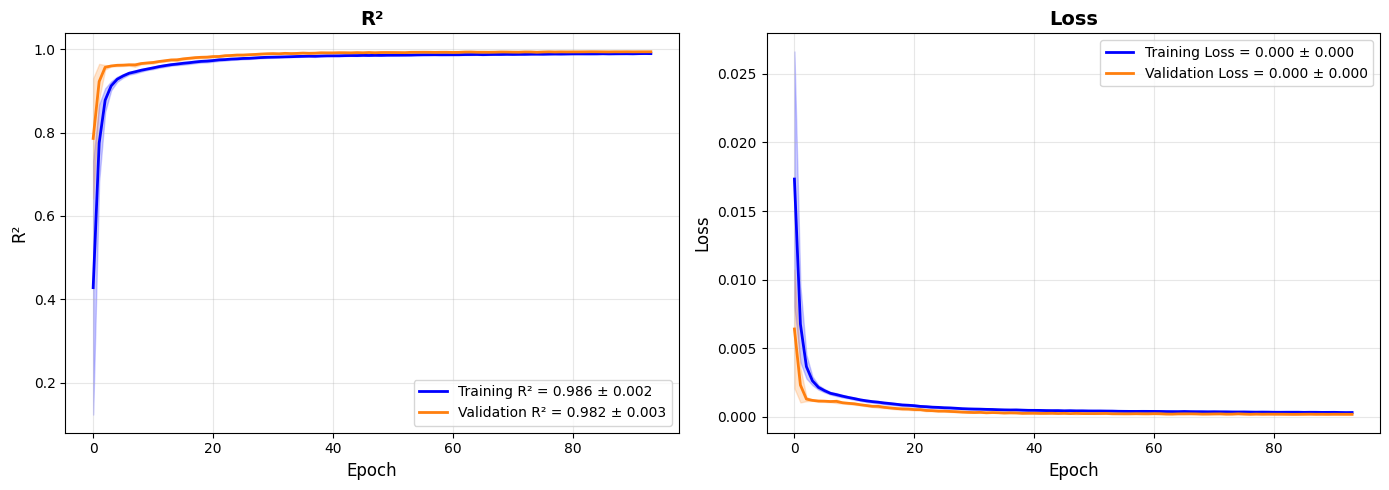

In [25]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'models/aidaying_iml1515_UB_AMN_QP/result'
fig = plot_learning_curve(result_path)

Found 5 history files.
Using first 94 epochs.


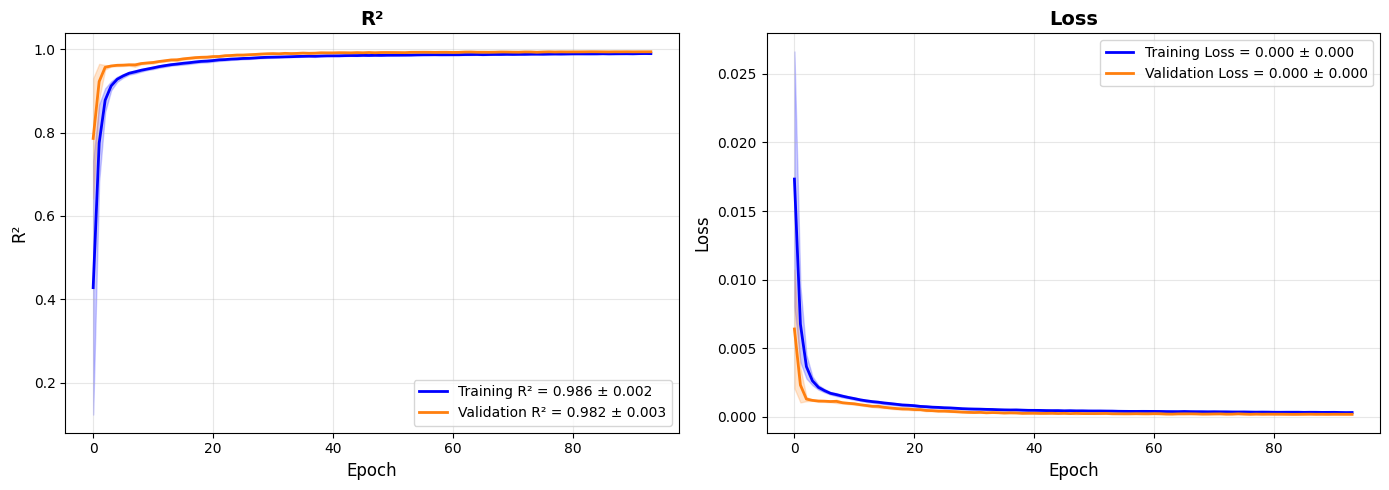

In [26]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'experiments/aidaying_iml1515_UB_AMN_QP-March11/result'
fig = plot_learning_curve(result_path)

Found 5 history files.


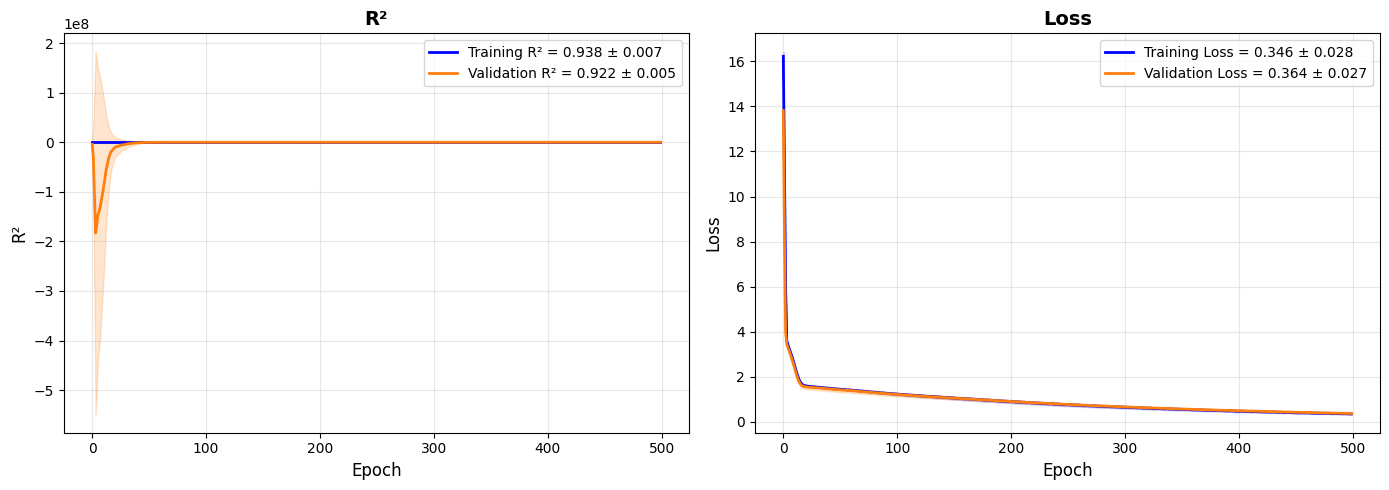

In [27]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'experiments/aidaying_iml1515_UB_AMN_QP-March10/result'
fig = plot_learning_curve(result_path)

## Step 5.  Get predictions using experimental data + reservoir model

### 5.1 Create stratified growth splits

This ensures that each fold contains a representative distribution of the target variable (growth rates) to prevent biases where one fold might only contain high or low growth rates

In [40]:
from src.Build_Dataset import read_XY

trainingfile = DATA_INTERIM_DIR / 'aidaying_media_growth_amns_padded'

X, Y = read_XY(str(trainingfile), 48)

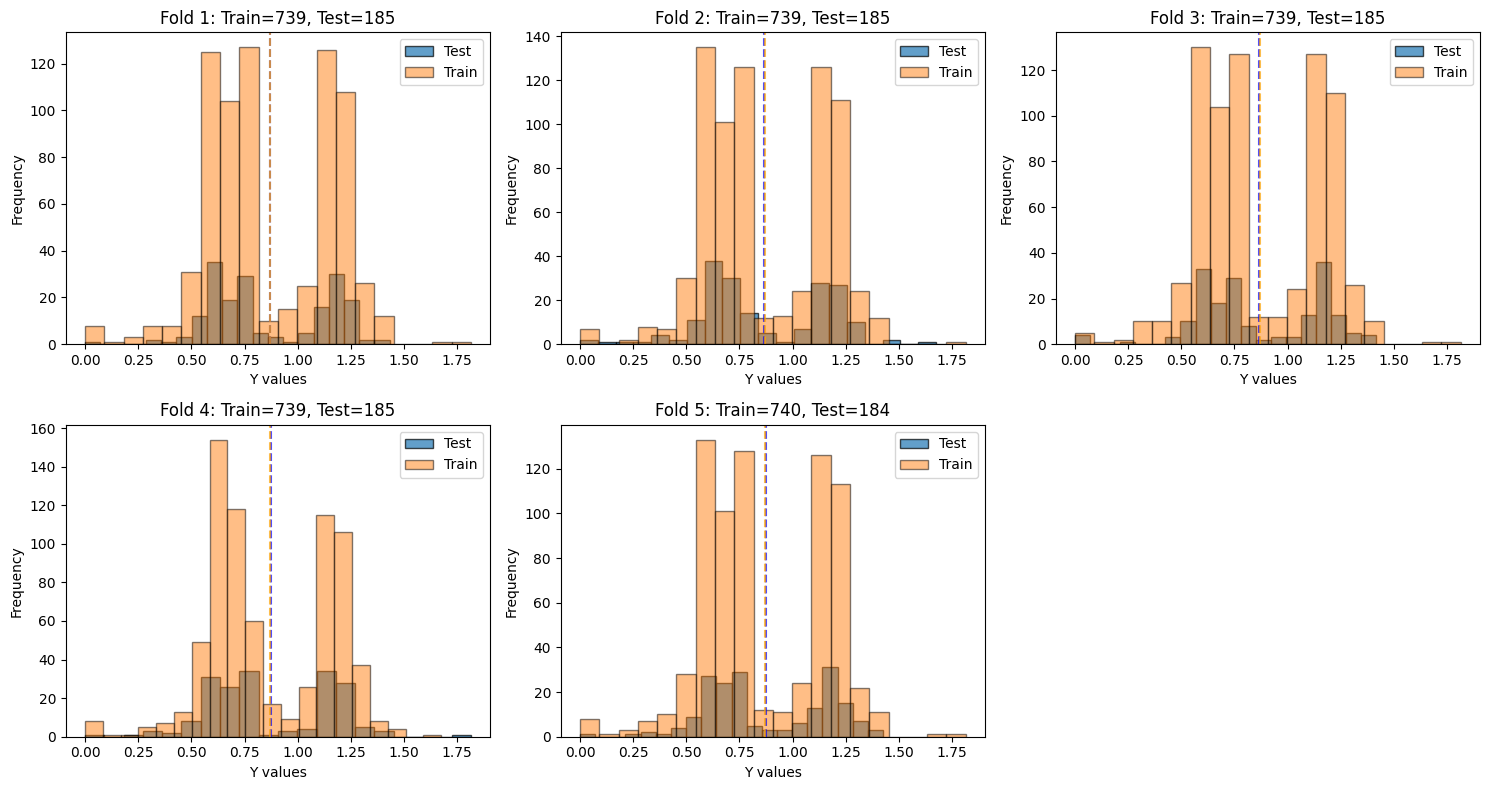

In [44]:
from src.Build_Model import get_stratified_kfold

kfold, y_binned = get_stratified_kfold(Y, n_splits=5, 
                                       n_bins=10, shuffle=True)

# Plot 2: Y distribution in each fold
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for fold_idx, (train_idx, test_idx) in enumerate(kfold.split(X, y_binned)):
    # Plot test set distribution for this fold
    axes[fold_idx].hist(Y[test_idx].flatten(), bins=20, alpha=0.7, 
                        edgecolor='black', label='Test')
    axes[fold_idx].hist(Y[train_idx].flatten(), bins=20, alpha=0.5, 
                        edgecolor='black', label='Train')
    axes[fold_idx].set_xlabel('Y values')
    axes[fold_idx].set_ylabel('Frequency')
    axes[fold_idx].set_title(f'Fold {fold_idx+1}: Train={len(train_idx)}, Test={len(test_idx)}')
    axes[fold_idx].legend()
    
    # Add statistics
    test_mean = Y[test_idx].mean()
    train_mean = Y[train_idx].mean()
    axes[fold_idx].axvline(test_mean, color='blue', linestyle='--', alpha=0.7)
    axes[fold_idx].axvline(train_mean, color='orange', linestyle='--', alpha=0.7)

# Hide extra subplot
if len(axes) > 5:
    axes[5].axis('off')

plt.tight_layout()
plt.show()

### 5.2 Create, train and evaluate reservoir models on experimental training set 

Training process is repeated with different seeds (using 3). Because the experimental dataset is smaller (~900 datapoints) than the FBA-generated (~9k), repeating the process with different seeds will allow to get a trustworthy performance estimate, ensuring the results aren't an artifact of one unlucky split.

This process requires GPU and can be run with the script and config file:

```
python scripts/train_eval_ensemble.py configs/ensemble_params.yaml
```

Found 15 history files.
Using first 358 epochs.


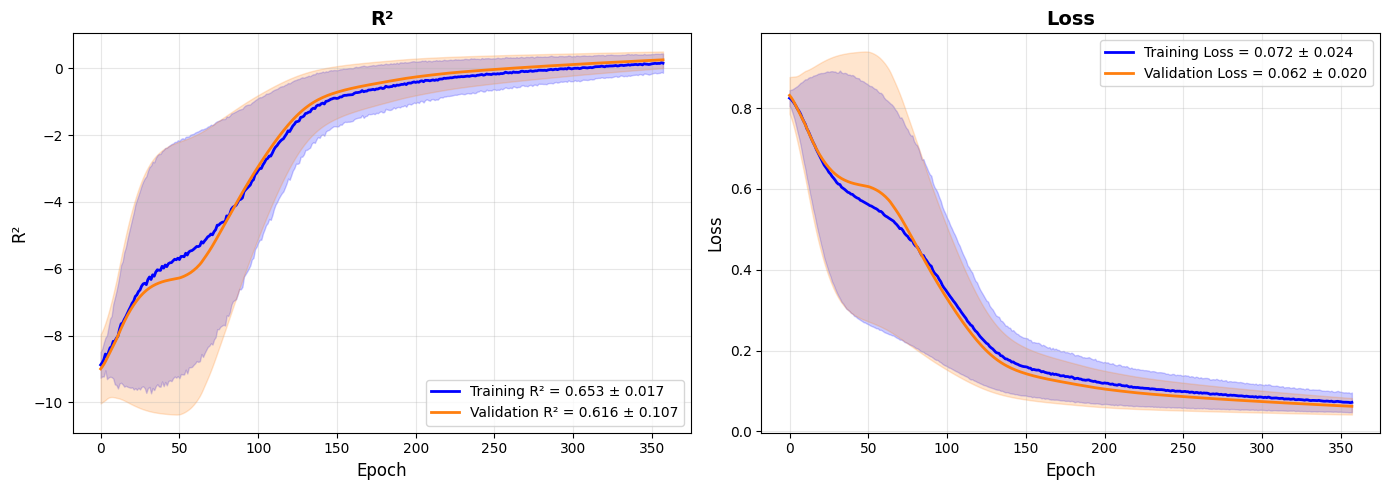

In [22]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'models/aidaying_iml1515_UB_AMN_QP/result_ensemble' # March 12
fig = plot_learning_curve(result_path)

Found 15 history files.
Using first 687 epochs.


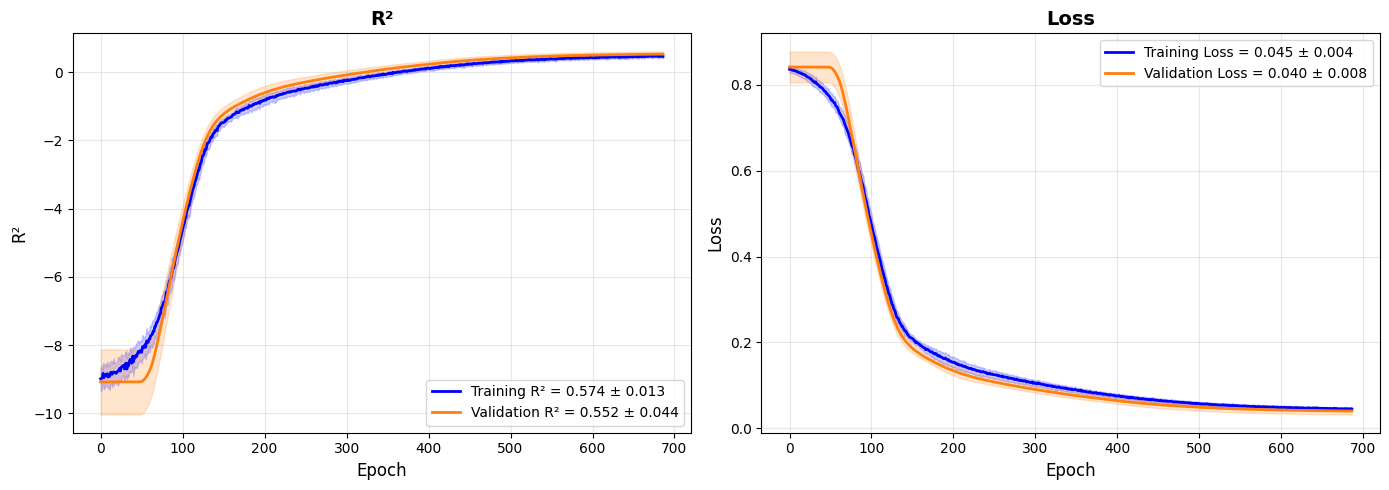

In [23]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'experiments/aidaying_iml1515_UB_AMN_QP-March10/result_ensemble'
fig = plot_learning_curve(result_path)

Found 15 history files.
Using first 372 epochs.


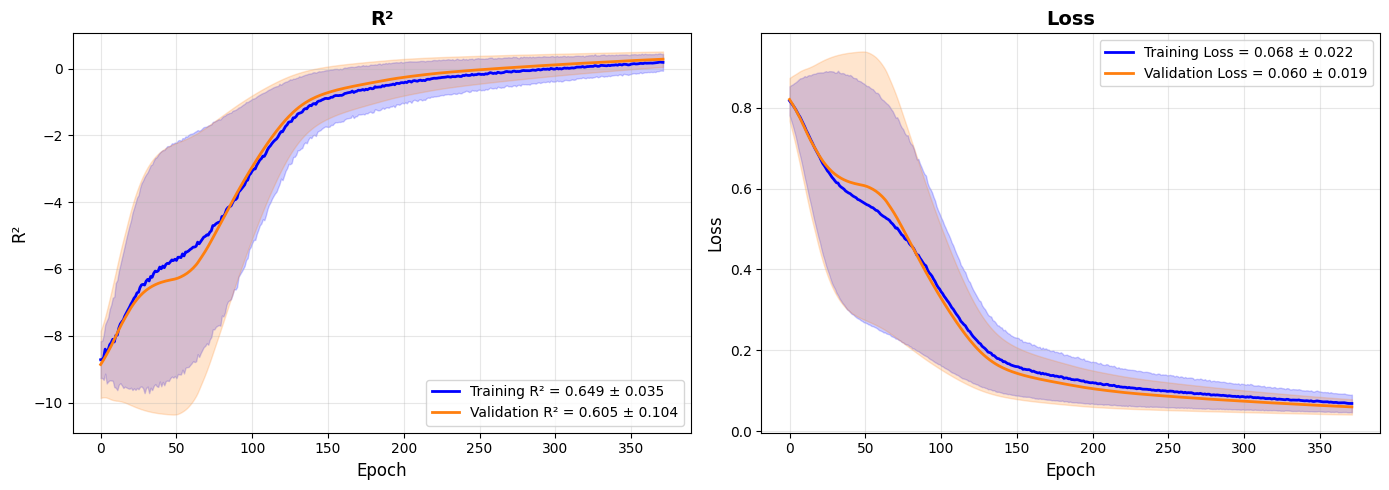

In [24]:
from src.plots import plot_learning_curve

result_path = PROJECT_ROOT / 'experiments/aidaying_iml1515_UB_AMN_QP-March11/result_ensemble'
fig = plot_learning_curve(result_path)

## Step 6. Use RC predictions as input for COBRApy

The goal of this last validation is to get a better growth rate estimates, when constraining the GEM with predicted medium fluxes.

To do this, we will run COBRApy FBA on a provided training and compute R2 between the experimental and the predicted growth.

For exprimental training set medium input fluxes can be scaled by a value.


In [29]:
from src.Build_Dataset import *

# Set parameters
seed = 10
np.random.seed(seed=seed)  # seed for random number generator
cobraname =  'iML1515' # name of the model 
mediumbound = 'UB' # Exact bound (EB) or upper bound (UB)
expname = 'aidaying_iml1515_UB_AMN_QP_solution_for_Cobra' # solution from ensemble model
mediumsize = 48 # number of medium compounds
verbose = True # prints

# Get X from experimental dataset
cobrafile = DATA_RAW_DIR / cobraname # .xml
#expfile  = DATA_INTERIM_DIR / expname # .csv
expfile = PROJECT_ROOT / 'models/aidaying_iml1515_UB_AMN_QP/result_medium/pred_medium_seed2'

# Generate a parameter object with the experimental data
parameter = TrainingSet(cobraname=str(cobrafile), 
                        mediumname=str(expfile), 
                        mediumbound=mediumbound, 
                        mediumsize=mediumsize, 
                        method='EXP',
                        verbose=verbose)

scaler_list = [1] # best scaler for RC EXP input

medium: ['EX_glc__D_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i', 'EX_asn__L_e_i', 'EX_asp__L_e_i', 'EX_glu__L_e_i', 'EX_gln__L_e_i', 'EX_gly_e_i', 'EX_his__L_e_i', 'EX_ile__L_e_i', 'EX_leu__L_e_i', 'EX_lys__L_e_i', 'EX_met__L_e_i', 'EX_phe__L_e_i', 'EX_pro__L_e_i', 'EX_ser__L_e_i', 'EX_thr__L_e_i', 'EX_trp__L_e_i', 'EX_tyr__L_e_i', 'EX_val__L_e_i', 'EX_thm_e_i', 'EX_pydxn_e_i', 'EX_cys__L_e_i', 'EX_cl_e_i', 'EX_nh4_e_i', 'EX_so4_e_i', 'EX_pi_e_i', 'EX_k_e_i', 'EX_na1_e_i', 'EX_mg2_e_i', 'EX_ca2_e_i', 'EX_fe2_e_i', 'EX_zn2_e_i', 'EX_cu2_e_i', 'EX_mobd_e_i', 'EX_cit_e_i', 'EX_tsul_e_i', 'EX_o2_e_i', 'EX_co2_e_i', 'EX_h_e_i', 'EX_h2o_e_i', 'EX_fe3_e_i', 'EX_mn2_e_i', 'EX_ni2_e_i', 'EX_sel_e_i', 'EX_cobalt2_e_i', 'EX_tungs_e_i', 'EX_slnt_e_i']
levmed: []
valmed: []
ratmed: 0
objective:  ['BIOMASS_Ec_iML1515_core_75p37M']
measurements size:  2712


In [30]:
# Regression COBRApy predicted vs. true values
L = parameter.X.shape[0]
for scaler in scaler_list:
    Y = {}
    for i in range(L):
        inf = {r.id: 0 for r in parameter.model.reactions}
        for j in range(len(parameter.medium)):
            print(j, parameter.medium[j],parameter.X[i,j], len(parameter.model.reactions))
            eps = 1.0e-4 if parameter.X[i,j] < 1.0e-4 else 0
            inf[parameter.medium[j]] = scaler * parameter.X[i,j] + eps
        out,Y[i] = run_cobra(parameter.model, parameter.objective, inf, method='pFBA', verbose=False)
        print("%d %.4f %.4f" % (i, parameter.Y[i].item(), Y[i].item()))

    Y = list(Y.values())
    r2 = r2_score(parameter.Y[0:L], Y[0:L], multioutput='variance_weighted')
    print('scaler %.2f R2 %.4f ' % (scaler, r2))

0 EX_glc__D_e_i 2.200000065565109 2712
1 EX_ala__L_e_i 2.200000065565109 2712
2 EX_arg__L_e_i 2.200000065565109 2712
3 EX_asn__L_e_i 2.200000065565109 2712
4 EX_asp__L_e_i 2.200000065565109 2712
5 EX_glu__L_e_i 2.200000065565109 2712
6 EX_gln__L_e_i 2.200000065565109 2712
7 EX_gly_e_i 2.200000065565109 2712
8 EX_his__L_e_i 2.200000065565109 2712
9 EX_ile__L_e_i 2.200000065565109 2712
10 EX_leu__L_e_i 2.200000065565109 2712
11 EX_lys__L_e_i 2.200000065565109 2712
12 EX_met__L_e_i 2.200000065565109 2712
13 EX_phe__L_e_i 2.200000065565109 2712
14 EX_pro__L_e_i 2.200000065565109 2712
15 EX_ser__L_e_i 2.200000065565109 2712
16 EX_thr__L_e_i 2.200000065565109 2712
17 EX_trp__L_e_i 2.200000065565109 2712
18 EX_tyr__L_e_i 2.200000065565109 2712
19 EX_val__L_e_i 2.200000065565109 2712
20 EX_thm_e_i 2.200000065565109 2712
21 EX_pydxn_e_i 2.200000065565109 2712
22 EX_cys__L_e_i 2.200000065565109 2712
23 EX_cl_e_i 2.200000065565109 2712
24 EX_nh4_e_i 2.200000065565109 2712
25 EX_so4_e_i 2.20000006

Infeasible: None (infeasible).